# Chương 5 bài 1 SVM tiểu đường

**Nguồn:** Lab phân lớp, mục 2.2.3, trang 12

**Đề bài:** Xây dựng mô hình SVM trên dữ liệu bệnh tiểu đường.

Code triển khai bài tập theo dữ liệu đã cung cấp; không phải đoạn chép nguyên văn bài mẫu.

In [1]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / 'data').is_dir() and (p / 'README.md').is_file())
DATA = ROOT / 'data'
OUT = ROOT / 'ket_qua' / 'C5_BT01_SVM_TieuDuong'
OUT.mkdir(parents=True, exist_ok=True)
sns.set_theme(style='whitegrid')
plt.rcParams.update({'figure.dpi': 100, 'figure.figsize': (8, 4)})

def save_fig(name):
    plt.tight_layout()
    plt.savefig(OUT / name, dpi=140, bbox_inches='tight')
    plt.show()

def save_summary(values):
    (OUT / 'tom_tat.json').write_text(
        json.dumps(values, ensure_ascii=False, indent=2), encoding='utf-8'
    )


## 1 Đọc và kiểm tra Pima

In [2]:
columns = ['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness',
           'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']
raw = pd.read_csv(DATA / 'pima-indians-diabetes.csv', header=None, names=columns)
invalid_zero = ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']
zero_counts = raw[invalid_zero].eq(0).sum()
df = raw.copy()
df[invalid_zero] = df[invalid_zero].replace(0, np.nan)
print('Raw shape:', raw.shape)
print('Zero placeholders:\n', zero_counts)
print('Class distribution:\n', df['Outcome'].value_counts())

X = df.drop(columns='Outcome')
y = df['Outcome']

Raw shape: (768, 9)
Zero placeholders:
 Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64
Class distribution:
 Outcome
0    500
1    268
Name: count, dtype: int64


## 2 Chia dữ liệu

In [3]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print('Train:', X_train.shape, 'Test:', X_test.shape)
print('Test classes:', y_test.value_counts().to_dict())

Train: (614, 8) Test: (154, 8)
Test classes: {0: 100, 1: 54}


## 3 Điền thiếu và chuẩn hóa theo train

In [4]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
imputer = SimpleImputer(strategy='median')
scaler = StandardScaler()
X_train_filled = imputer.fit_transform(X_train)
X_test_filled = imputer.transform(X_test)
X_train_ready = scaler.fit_transform(X_train_filled)
X_test_ready = scaler.transform(X_test_filled)

## 4 Xây dựng mô hình

In [5]:
from sklearn.svm import SVC
# Fixed parameters, not a claim of optimal tuning.
model = SVC(kernel='rbf', C=1.0, gamma='scale', probability=True,
            random_state=42, class_weight='balanced')
model.fit(X_train_ready, y_train)

SVC(class_weight='balanced', probability=True, random_state=42)


## 5 Đánh giá

accuracy             0.7273
precision            0.5909
recall               0.7222
f1                   0.6500
roc_auc              0.8139
recall_negative      0.7300
balanced_accuracy    0.7261
average_precision    0.6774
dtype: float64
              precision    recall  f1-score   support

           0       0.83      0.73      0.78       100
           1       0.59      0.72      0.65        54

    accuracy                           0.73       154
   macro avg       0.71      0.73      0.71       154
weighted avg       0.75      0.73      0.73       154



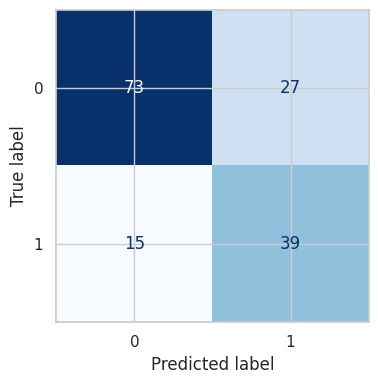

In [6]:
from sklearn.metrics import balanced_accuracy_score
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, average_precision_score,
                             classification_report, ConfusionMatrixDisplay)
pred = model.predict(X_test_ready)
prob = model.predict_proba(X_test_ready)[:, list(model.classes_).index(1)]
metrics = {'accuracy':float(accuracy_score(y_test,pred)),
           'precision':float(precision_score(y_test,pred,zero_division=0)),
           'recall':float(recall_score(y_test,pred,zero_division=0)),
           'f1':float(f1_score(y_test,pred,zero_division=0)),
           'roc_auc':float(roc_auc_score(y_test,prob)),
           'recall_negative':float(recall_score(y_test,pred,pos_label=0,zero_division=0)),
                 'balanced_accuracy':float(balanced_accuracy_score(y_test,pred)),
                 'average_precision':float(average_precision_score(y_test,prob))}
print(pd.Series(metrics).round(4))
print(classification_report(y_test,pred,zero_division=0))
pd.DataFrame([metrics]).to_csv(OUT / 'metrics.csv',index=False)
ConfusionMatrixDisplay.from_predictions(y_test,pred,cmap='Blues',colorbar=False)
save_fig('01_confusion_matrix.png')
save_summary({'train_rows':len(y_train),'test_rows':len(y_test),
              'positive_label':1, 'metrics':metrics})

## Nhận xét và giới hạn
Tham số RBF, C=1 và gamma=scale đặt trước, không chọn bằng test. class_weight=balanced cân bằng trọng số lớp theo train. Chuẩn hóa chỉ học từ train. Xem recall/F1 và độ chính xác cùng nhau; đây là bài tập trên dữ liệu, không phải công cụ chẩn đoán.